# 02 - Features, models and evaluation

**Goal:** rank at-risk households by churn risk so a limited coupon budget goes to those most likely to stop shopping.
Code: `src/features.py` (labels + features), `src/train.py` (preprocessing, validation, evaluation).

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Run from the repo root whether the notebook is opened from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.config import FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 1. Build the model table

For each **snapshot** week *c* (30, 38, ..., 94) we take the households at risk at *c*, compute features using **only weeks <= c**,
and the label from weeks *c+1 .. c+8*. Stacking the snapshots gives more training data. Demographics are joined on `household_key`.

In [2]:
from src.features import (BEHAVIOUR_FEATURES, CATEGORICAL_DEMOGRAPHICS, FEATURES,
                          NUMERIC_DEMOGRAPHICS, build_model_table, load_inputs)

table = build_model_table(*load_inputs())
print(f"{len(table):,} rows, {table['household_key'].nunique():,} households, overall churn rate {table['churn'].mean():.1%}")
print(f"behaviour features: {len(BEHAVIOUR_FEATURES)} | demographic features: {len(NUMERIC_DEMOGRAPHICS) + len(CATEGORICAL_DEMOGRAPHICS)}")
table.groupby("cutoff_week")["churn"].agg(households="size", churn_rate="mean")

20,588 rows, 2,485 households, overall churn rate 7.2%
behaviour features: 12 | demographic features: 5


,households,churn_rate
cutoff_week,,
30,2288,0.080
38,2275,0.076
46,2258,0.072
54,2267,0.065
62,2280,0.068
70,2306,0.074
78,2302,0.066
86,2296,0.068
94,2316,0.082


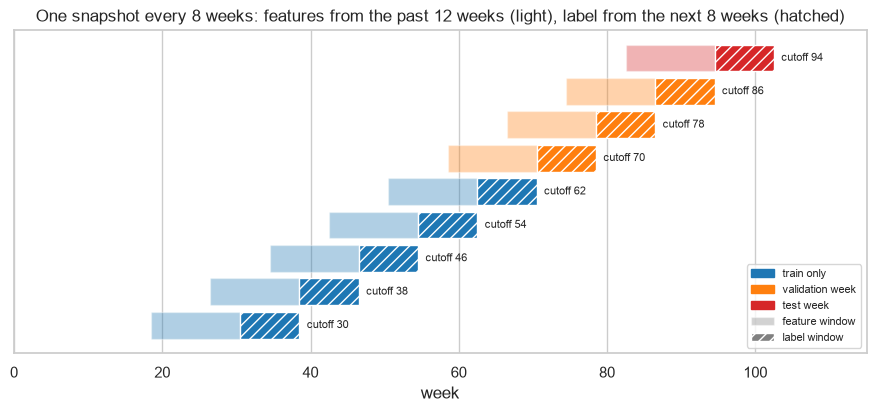

In [3]:
from matplotlib.patches import Patch
from src.config import OBSERVATION_WEEKS, PREDICTION_WEEKS, TEST_CUTOFF, VALID_CUTOFFS

cutoffs = sorted(table["cutoff_week"].unique())
colors = {"train only": "tab:blue", "validation week": "tab:orange", "test week": "tab:red"}
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, c in enumerate(cutoffs):
    role = "test week" if c == TEST_CUTOFF else "validation week" if c in VALID_CUTOFFS else "train only"
    ax.barh(i, OBSERVATION_WEEKS, left=c - OBSERVATION_WEEKS + 0.5, color=colors[role], alpha=0.35)   # features
    ax.barh(i, PREDICTION_WEEKS, left=c + 0.5, color=colors[role], hatch="///", edgecolor="white")    # label
    ax.text(c + PREDICTION_WEEKS + 1.5, i, f"cutoff {c}", va="center", fontsize=8)
ax.set(yticks=[], xlim=(0, 115), xlabel="week",
       title="One snapshot every 8 weeks: features from the past 12 weeks (light), label from the next 8 weeks (hatched)")
ax.legend(handles=[Patch(color=v, label=k) for k, v in colors.items()]
          + [Patch(facecolor="grey", alpha=0.35, label="feature window"), Patch(facecolor="grey", hatch="///", label="label window")],
          loc="lower right", fontsize=8)
fig.savefig(FIGURES_DIR / "snapshot_timeline.png", dpi=120, bbox_inches="tight")
plt.show()

Label windows never overlap between snapshots. A validation week is always scored by a model trained only on the
snapshots **before** it, and the test week (94) is used only once, at the very end.

## 2. Do the features separate churners from non-churners?

In [4]:
table.groupby("churn")[BEHAVIOUR_FEATURES + ["income_k"]].median().T

churn,0,1
recency_weeks,0.000,3.000
tenure_weeks,53.000,54.000
active_share,0.607,0.242
active_weeks_4w,3.000,1.000
active_weeks_12w,8.000,2.000
baskets_12w,11.000,2.000
sales_12w,322.395,55.695
avg_basket_value_12w,26.748,19.348
trend_4w_vs_12w,0.000,-0.083
discount_share_12w,0.147,0.133


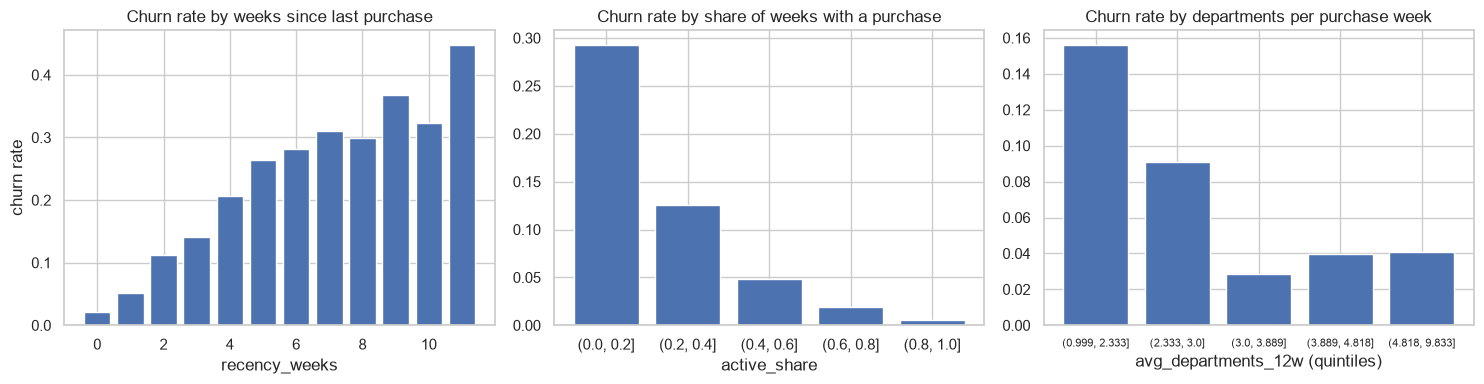

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

by_recency = table.groupby("recency_weeks")["churn"].mean()
axes[0].bar(by_recency.index, by_recency.values)
axes[0].set(title="Churn rate by weeks since last purchase", xlabel="recency_weeks", ylabel="churn rate")

share_bin = pd.cut(table["active_share"], [0, 0.2, 0.4, 0.6, 0.8, 1.0])
by_share = table.groupby(share_bin, observed=True)["churn"].mean()
axes[1].bar(by_share.index.astype(str), by_share.values)
axes[1].set(title="Churn rate by share of weeks with a purchase", xlabel="active_share")

dept_bin = pd.qcut(table["avg_departments_12w"], 5, duplicates="drop")
by_dept = table.groupby(dept_bin, observed=True)["churn"].mean()
axes[2].bar(by_dept.index.astype(str), by_dept.values)
axes[2].set(title="Churn rate by departments per purchase week", xlabel="avg_departments_12w (quintiles)")
axes[2].tick_params(axis="x", labelsize=8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "churn_rate_by_feature.png", dpi=120, bbox_inches="tight")
plt.show()

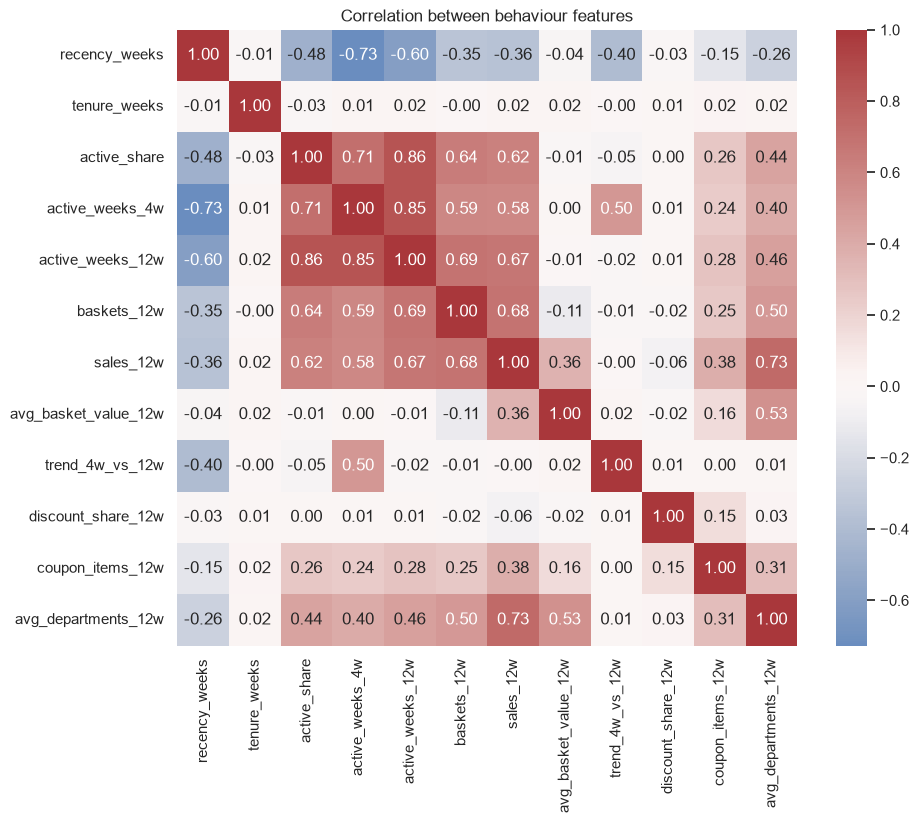

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(table[BEHAVIOUR_FEATURES].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation between behaviour features")
plt.show()

In [7]:
table.groupby(table["has_demographics"].map({0: "no demographics", 1: "has demographics"}))["churn"].agg(["size", "mean"])

,size,mean
has_demographics,,
has demographics,7132,0.010
no demographics,13456,0.106


* Churn rises clearly with recency and falls with how regularly a household shops, and with how many departments it buys from
  (households that do only a small part of their shopping here are easier to lose).
* Some features are strongly correlated (e.g. `active_weeks_12w` and `baskets_12w`): fine for ranking, but careful when reading logistic coefficients.
* **Warning sign:** households *with* demographics almost never churn (~1% vs ~11%). The demographic survey was probably answered by
  loyal, engaged households, so "has demographics" may partly encode the future. We test below how much the model depends on it.

## 3. Preprocessing pipeline

One `ColumnTransformer` inside each model's `Pipeline`, so it is **fitted on the training data only** (no information from validation/test leaks in):

| Columns | Steps |
|---|---|
| skewed counts and amounts (`sales_12w`, `baskets_12w`, ...) | `log1p` -> standardize |
| other numeric, incl. `income_k`, `household_size` | median imputation -> standardize |
| `age_group`, `homeowner` | fill missing with "unknown" -> one-hot (unknown categories at prediction time are ignored) |

In [8]:
from src.train import make_preprocessor, time_split

dev, test = time_split(table)
prep = make_preprocessor().fit(dev[FEATURES])
X_dev = pd.DataFrame(prep.transform(dev[FEATURES]), columns=prep.get_feature_names_out())
print(f"{len(FEATURES)} input columns -> {X_dev.shape[1]} model columns")
X_dev.describe().T[["mean", "std", "min", "max"]].head(8)

17 input columns -> 25 model columns


,mean,std,min,max
baskets_12w,-1.991e-16,1.0,-1.881,3.401
sales_12w,7.777e-18,1.0,-3.923,2.520
avg_basket_value_12w,4.219e-16,1.0,-4.177,3.544
coupon_items_12w,-1.867e-17,1.0,-0.624,4.979
recency_weeks,2.178e-17,1.0,-0.571,4.328
tenure_weeks,4.978e-17,1.0,-2.524,1.943
active_share,1.649e-16,1.0,-2.050,1.600
active_weeks_4w,2.489e-17,1.0,-1.673,1.213


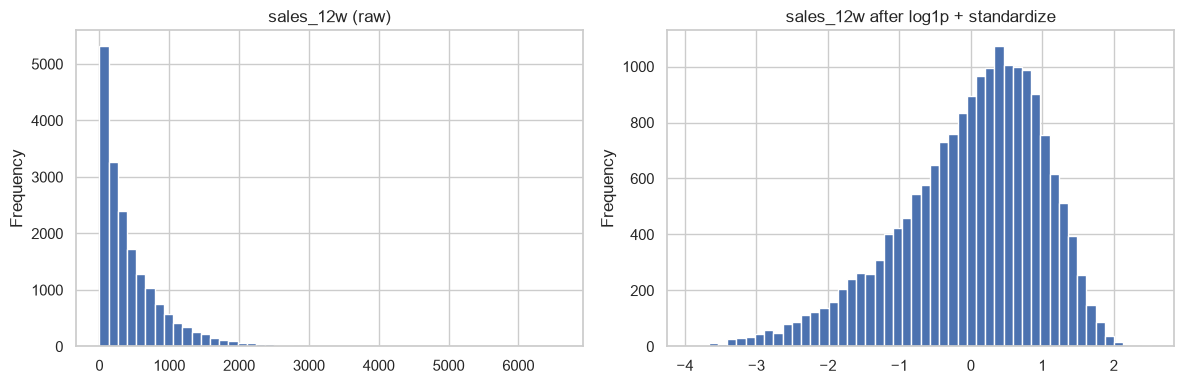

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dev["sales_12w"].plot.hist(bins=50, ax=axes[0], title="sales_12w (raw)")
X_dev["sales_12w"].plot.hist(bins=50, ax=axes[1], title="sales_12w after log1p + standardize")
fig.tight_layout()
plt.show()

## 4. Validation on 3 weeks and model choice

* **dev** = snapshots 30..86, **test** = snapshot 94 (reported once, at the end).
* **Validation:** for each setting of each model, train on the snapshots before week 70 and score week 70, then the same for
  weeks 78 and 86. The setting's score is the **average** of the 3 PR-AUCs: one week has only ~150 churners, so a single week is noisy.
* No random k-fold: the same household appears in several snapshots, and in real life we predict the future from the past.
* Churn is rare (~7%), so accuracy is useless (predicting "no churn" for everyone gives 93%). We use **PR-AUC** and also report
  **precision in the top 10%**, **lift** (how many times better than a random 10%) and ROC-AUC.

In [10]:
from src.train import GRIDS

for name, grid in GRIDS.items():
    print(f"{name:14s} {np.prod([len(v) for v in grid.values()])} settings: {grid}")

logistic       4 settings: {'clf__C': [0.01, 0.1, 1, 10]}
random_forest  9 settings: {'clf__max_depth': [4, 8, 12], 'clf__min_samples_leaf': [20, 50, 100]}
lightgbm       6 settings: {'clf__num_leaves': [7, 15, 31], 'clf__learning_rate': [0.02, 0.05]}


In [11]:
from src.train import tune

print(f"dev {len(dev):,} rows | test {len(test):,} rows")
best = tune(dev)
best

dev 18,272 rows | test 2,316 rows


logistic       {'clf__C': 0.01}                                        valid PR-AUC 0.328


logistic       {'clf__C': 0.1}                                         valid PR-AUC 0.333


logistic       {'clf__C': 1}                                           valid PR-AUC 0.334


logistic       {'clf__C': 10}                                          valid PR-AUC 0.332


...

lightgbm       {'clf__learning_rate': 0.02, 'clf__num_leaves': 31}     valid PR-AUC 0.321


lightgbm       {'clf__learning_rate': 0.05, 'clf__num_leaves': 7}      valid PR-AUC 0.326


lightgbm       {'clf__learning_rate': 0.05, 'clf__num_leaves': 15}     valid PR-AUC 0.314


lightgbm       {'clf__learning_rate': 0.05, 'clf__num_leaves': 31}     valid PR-AUC 0.306


,params,valid_pr_auc
model,,
recency_rule,{},0.251
logistic,{'clf__C': 1},0.334
random_forest,"{'clf__max_depth': 12, 'clf__min_samples_leaf'...",0.348
lightgbm,"{'clf__learning_rate': 0.02, 'clf__num_leaves'...",0.338


All three ML models (logistic regression, random forest, LightGBM) beat the simple recency rule on validation, and they are close to each other.
The rule is "choose on validation, not on test": the model with the best validation score is kept.
Now every model is trained on all dev snapshots and evaluated **once** on the test week.

In [12]:
from src.train import build_model, evaluate

scores = {}
for name, row in best.iterrows():
    model = build_model(name, row["params"]).fit(dev[FEATURES], dev["churn"])
    scores[name] = model.predict_proba(test[FEATURES])[:, 1]
test_results = pd.DataFrame({name: evaluate(test["churn"], s) for name, s in scores.items()}).T
test_results

,roc_auc,pr_auc,precision_top10,lift_top10
recency_rule,0.763,0.234,0.316,3.872
logistic,0.857,0.322,0.372,4.562
random_forest,0.856,0.329,0.364,4.456
lightgbm,0.857,0.333,0.372,4.562


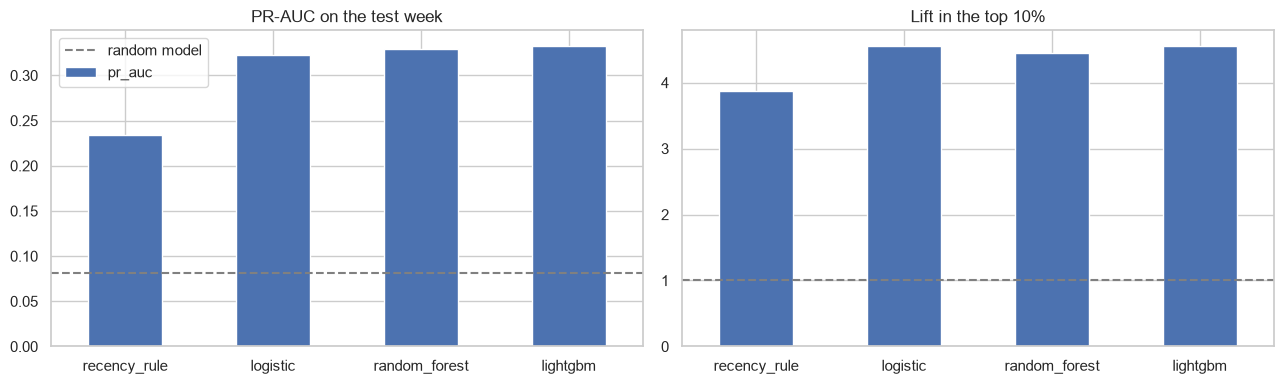

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
test_results["pr_auc"].plot.bar(ax=axes[0], rot=0, title="PR-AUC on the test week")
axes[0].axhline(test["churn"].mean(), ls="--", c="grey", label="random model")
axes[0].legend()
test_results["lift_top10"].plot.bar(ax=axes[1], rot=0, title="Lift in the top 10%")
axes[1].axhline(1, ls="--", c="grey")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

On test, the three ML models are within ~0.01 PR-AUC of each other: the gain over the recency rule is real, the differences between
models are mostly noise (notebook 04 shows the bootstrap intervals).

### Experiment: how much do the demographics help?

Same model and settings, validated once with and once without the demographic columns (they are blanked out).
If the model without them is almost as good, we do not depend on the suspicious "has demographics" signal.

In [14]:
from src.features import CATEGORICAL_DEMOGRAPHICS, NUMERIC_DEMOGRAPHICS
from src.train import validation_score

def blank_demographics(df):
    out = df.copy()
    out[NUMERIC_DEMOGRAPHICS] = 0              # the same value for everyone = no information
    out[CATEGORICAL_DEMOGRAPHICS] = "unknown"
    return out

chosen = best.drop("recency_rule")["valid_pr_auc"].idxmax()
params = best.loc[chosen, "params"]
ablation = {
    "with demographics": validation_score(build_model(chosen, params), dev),
    "without demographics": validation_score(build_model(chosen, params), blank_demographics(dev)),
}
pd.Series(ablation, name=f"{chosen}: validation PR-AUC").to_frame()

,random_forest: validation PR-AUC
with demographics,0.348
without demographics,0.349


Removing demographics changes the validation PR-AUC by almost nothing, so the model's signal comes from **purchase behaviour**.
Before using the model in production, check *when* demographics are collected; if after the prediction date, drop them.

## 5. A closer look at the chosen model

chosen model: random_forest {'clf__max_depth': 12, 'clf__min_samples_leaf': 50}


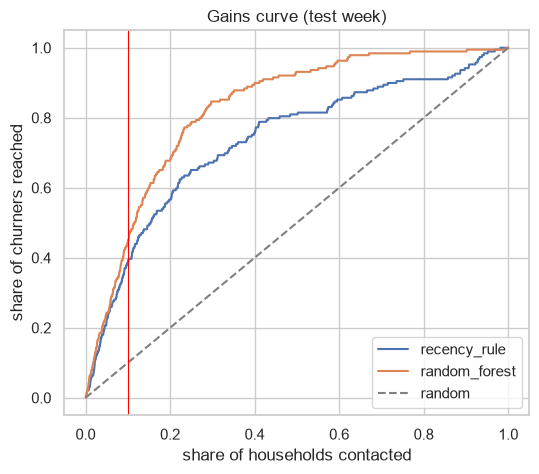

In [15]:
y = test["churn"].to_numpy()
print("chosen model:", chosen, params)

# Gains curve: if we contact the top x% of households by risk, what share of all churners do we reach?
share_contacted = np.arange(1, len(y) + 1) / len(y)
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["recency_rule", chosen]:
    order = np.argsort(-scores[name])
    ax.plot(share_contacted, np.cumsum(y[order]) / y.sum(), label=name)
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="random")
ax.axvline(0.10, c="red", lw=0.8)
ax.set(title="Gains curve (test week)", xlabel="share of households contacted", ylabel="share of churners reached")
ax.legend()
fig.savefig(FIGURES_DIR / "gains_curve.png", dpi=120, bbox_inches="tight")
plt.show()

In [16]:
from sklearn.metrics import confusion_matrix

# Turn the ranking into a decision: send a coupon to the top 10%
k = int(len(y) * 0.10)
selected = np.zeros(len(y), dtype=int)
selected[np.argsort(-scores[chosen])[:k]] = 1
pd.DataFrame(confusion_matrix(y, selected),
             index=["did not churn", "churned"], columns=["no coupon", "coupon (top 10%)"])

,no coupon,coupon (top 10%)
did not churn,1980,147
churned,105,84


## 6. The final model

The test numbers above come from models trained **before** week 94, so they are honest.
For real use, `python -m src.train` then refits the chosen settings on **all** labelled snapshots (including week 94),
so the saved model has seen the most recent behaviour. That saved model is used in notebook 03 and by `python -m src.predict`.

## Conclusions
* With the same budget, the model puts about **4.5x more** would-be churners in the top 10% than random targeting, and beats the "longest silence first" rule.
* Tuning and the extra features change the result only a little: most of the signal is in **recency and regularity**.